# Ultimate Inc. - Take Home Challenge

## Table of Contents
* [Part 1 - User Login Data EDA](#part-1---user-login-data-eda)
    * [Inspection of User Login Data](#inspection-of-user-login-data)
    * [Investigating Trends in Demand](#investigating-trends-in-demand)
    * [Report of Observations](#report-of-observations)
* [Part 2 - Gotham and Metropolis Driver Partner Experiment](#part-2---gotham-and-metropolis-driver-partner-experiment)
    * [Problem Description and Motivation](#problem-description-and-motivation)
    * [Key Success Metrics](#Key-Success-Metrics)
    * [Experimental Design](#experimental-design)
* [Part 3 - Predictive Modeling for Rider Churn](#part-3---predictive-modeling-for-rider-churn)
    * [Data Wrangling](#data-wrangling)
    * [Exploratory Data Analysis](#exploratory-data-analysis)
    * [Feature Engineering](#feature-engineering)
    * [Model Training and Evaluation](#Model-Training-and-Evaluation)
        * [Logistic Regression Classifier](#logistic-regression-classifier)
        * [Random Forest Classifier](#random-forest-classifier)
        * [K-Nearest Neighbors Classifier](#k-nearest-neighbors-classifier)
    * [Model Selection and Final Recommendations](#model-selection-and-final-recommendations)
        * [Model Selection Discussion](#Model-Selection-Discussion)
        * [Actionable Insights & Recommendations](Actionable-Insights-&-Recommendations)

### Import libraries

In [1]:
# Core
import json, os, warnings, datetime as dt
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

# Viz
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
%matplotlib inline    

# Modeling
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [2]:
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

# Part 1 - User Login Data EDA

## Inspection of User Login Data

In [3]:
# Load login data and inspect DataFrame
df = pd.read_json("../data/logins.json").sort_values(by='login_time').set_index('login_time')
display(df.head())
print(f"There are {df.shape[0]:,} rows.")

""
login_time
1970-01-01 20:12:16
1970-01-01 20:13:18
1970-01-01 20:16:10
1970-01-01 20:16:36
1970-01-01 20:16:37


There are 93,142 rows.


In [4]:
# Group logins into 15 minute intervals and log number of items in group
agg = df.groupby(pd.Grouper(freq='15Min')).size()
df = pd.DataFrame(agg).rename(columns={0:'demand'})

# Check completeness of groupings
expected_range = pd.date_range(df.index.min(), df.index.max(), freq='15min')
missing = expected_range.difference(df.index)
print(f"Missing time intervals: {len(missing)}")

# Add features relating to the change in demand
df['demand_diff'] = df['demand'].diff()
df['demand_pct_diff'] = df['demand'].pct_change()

# Add time-based features
df.reset_index(inplace=True)
df['month'] = df['login_time'].dt.month_name()
df['day'] = df['login_time'].dt.day_name()
df['hour'] = df['login_time'].dt.hour

# Inspect new DataFrame
df.head()

Missing time intervals: 0


,login_time,demand,demand_diff,demand_pct_diff,month,day,hour
0,1970-01-01 20:00:00,2,NaN,NaN,January,Thursday,20
1,1970-01-01 20:15:00,6,4.0,2.000000,January,Thursday,20
2,1970-01-01 20:30:00,9,3.0,0.500000,January,Thursday,20
3,1970-01-01 20:45:00,7,-2.0,-0.222222,January,Thursday,20
4,1970-01-01 21:00:00,1,-6.0,-0.857143,January,Thursday,21


In [5]:
# Print report of summary statistics
df['demand'].describe()

count    9788.000000
mean        9.515938
std         8.328818
min         0.000000
25%         3.000000
50%         7.000000
75%        13.000000
max        73.000000
Name: demand, dtype: float64

## Investigating Trends in Demand

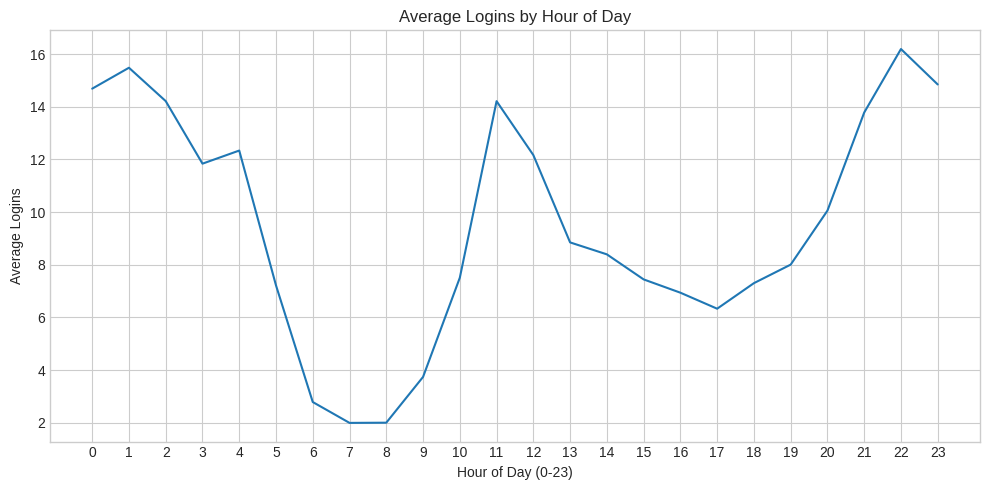

In [6]:
# Average logins per hour across all days
avg_hourly_demand = df.groupby('hour')['demand'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=avg_hourly_demand.index, y=avg_hourly_demand.values)
plt.title("Average Logins by Hour of Day")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Average Logins")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

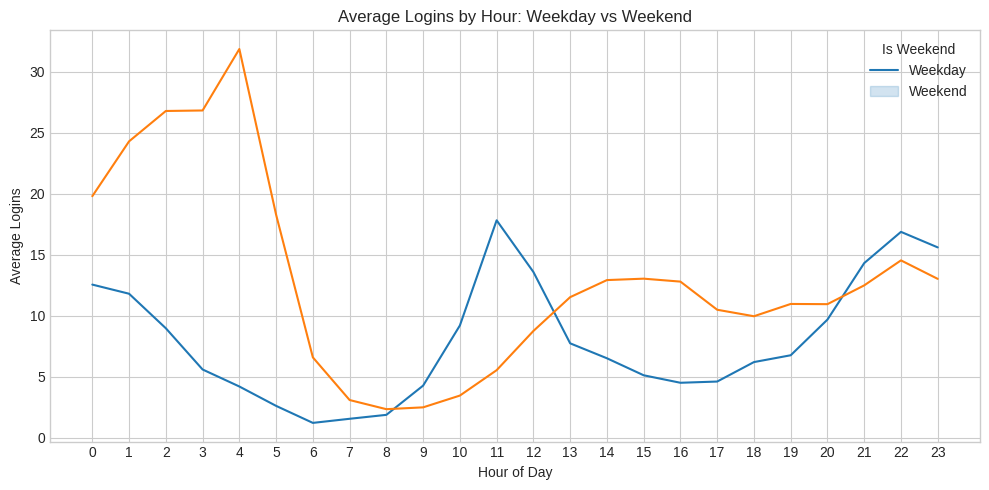

In [7]:
df['is_weekend'] = df['day'].isin(['Saturday', 'Sunday'])
hourly_split = df.groupby(['hour', 'is_weekend'])['demand'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_split, x='hour', y='demand', hue='is_weekend')
plt.title("Average Logins by Hour: Weekday vs Weekend")
plt.xlabel("Hour of Day")
plt.ylabel("Average Logins")
plt.legend(title="Is Weekend", labels=['Weekday', 'Weekend'])
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

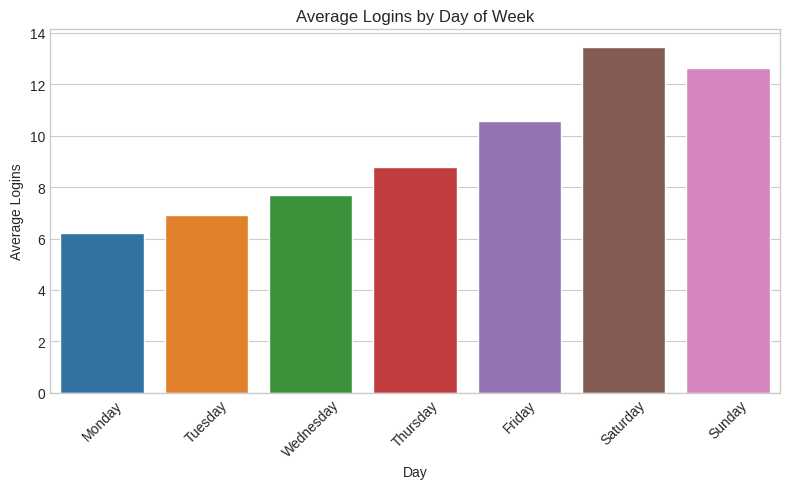

In [8]:
# Ensure correct weekday order
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
avg_daily_demand = df.groupby('day')['demand'].mean().reindex(day_order)

plt.figure(figsize=(8, 5))
sns.barplot(x=avg_daily_demand.index, y=avg_daily_demand.values, hue=avg_daily_demand.index)
plt.title("Average Logins by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Logins")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

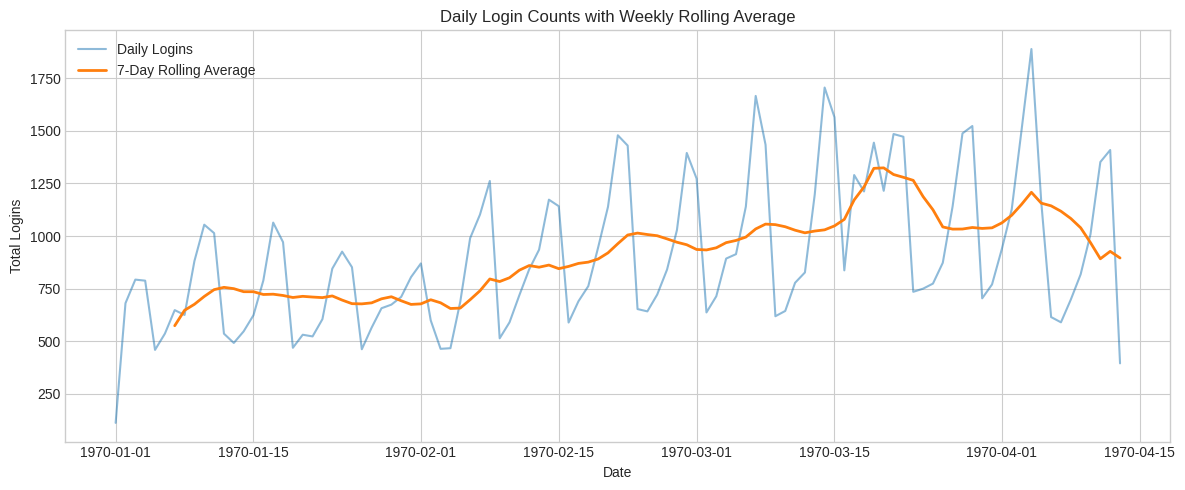

In [9]:
# Aggregate to daily totals
df['date'] = df['login_time'].dt.date
daily_counts = df.groupby('date')['demand'].sum()

# Rolling average over 7 days
rolling_avg = daily_counts.rolling(window=7).mean()

plt.figure(figsize=(12, 5))
plt.plot(daily_counts.index, daily_counts.values, label='Daily Logins', alpha=0.5)
plt.plot(rolling_avg.index, rolling_avg.values, label='7-Day Rolling Average', linewidth=2)
plt.title("Daily Login Counts with Weekly Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total Logins")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

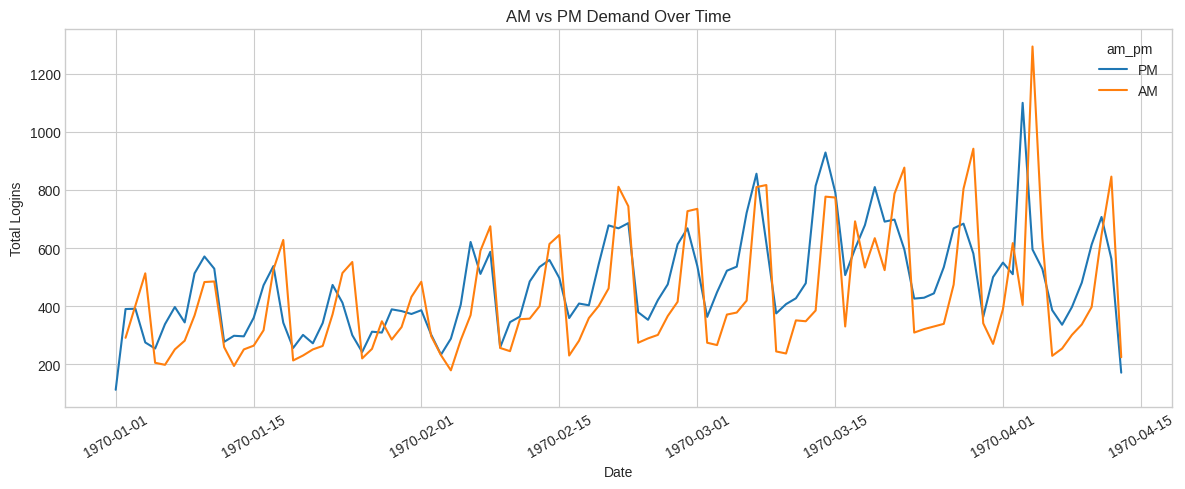

In [10]:
df['am_pm'] = df['hour'].apply(lambda x: 'AM' if x < 12 else 'PM')
am_pm_trend = df.groupby(['date', 'am_pm'])['demand'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=am_pm_trend, x='date', y='demand', hue='am_pm')
plt.title("AM vs PM Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Total Logins")
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()

## Report of Observations

### Key Findings
The analysis of login data reveals distinct cyclical patterns in user activity. The highest demand occurs during late-night hours, specifically between **10 PM** and **4 AM**, with a noticeable surge on weekends. There's a clear upward trend in logins throughout the week, culminating in a peak on Saturdays.


### Visualizing the Demand
To best illustrate these patterns, I've created a series of visualizations:

- **Average Logins by Hour**: This clearly shows the daily ebb and flow of user activity, highlighting the late-night peak.

- **Weekday vs. Weekend Logins by Hour**: This comparison emphasizes the intensified late-night usage on weekends.

- **Average Logins by Day of the Week**: This demonstrates the steady increase in logins from Monday to Saturday, followed by a slight dip on Sunday.

- **Daily Logins with a 7-Day Rolling Average**: This visualization smooths out daily fluctuations to reveal the overall increasing trend in user engagement over the observed period. * AM vs. PM Demand Over Time: This plot further confirms the dominance of nighttime activity.



### Data Quality
No significant data quality issues were identified in the `logins.json` dataset. The timestamps are consistent, and there are no apparent gaps in the data that would skew the analysis.

# Part 2 - Gotham and Metropolis Driver Partner Experiment

## Problem Description and Motivation
Ultimate Inc. is interested in encouraging trans-city activity between **Gotham** and **Metropolis** amongst their driver partners. They have determined that the critical barrier is the associated toll expenedures of such a trip. In order to encourage driver partners, management plans on experimenting with toll reimbursements. We must determine the effectiveness of toll reimbursement on encouraging driver partners to operate in both **Gotham** and **Metropolis**.

## Key Success Metrics
The primary metric for success will be the **percentage of driver partners who complete trips in both cities within a given week**. This metric would directly measure the desired outcome of our experiment: increased driver availability across both metroplitan areas. 

A secondary metric will be the **average number of trips per driver in their non-primary city**.

## Experimental Design
To test our experiment with our metrics in mind, we recommend the implementation of a **controlled A/B test**. Our experiment is conducted as follows:
1. **Hypnothesis**: Reimbursing toll costs for the bridge between Gotham and Metropolis will lead to a statistically siggnificant increase in the percentage of driver partners servering both cities.
2. **Implementation**:
    - **Random Assignment**: A sufficiently large and representative sample of active driver partners will be randomly divided into the following two groups.
        - **Control Group**: These drivers will not be offered toll reimbursement.
        - **Treatment Group**: These drivers wil be notified that all their toll costs for the bridge will be reimbursed.
    - **Duration**: The experiment should run for a minimum of four weeks to account for any novelty effects and to ggather suffecient data on driver behavior.
4. **Statistical Testing**:
    - A **two-sample z-test for proportions** will be used to compare the percentage of drivvers in the control and treament groups who serve in both cities. This test is appropriate for comparing the proportions of two independent groups.
6. **Interpreting the Results**:
    - If the p-value from the z-test is below a predetermined significance level (e.g., 0.05), we can reject our null hypothesis that toll reimbursement has no statistically significant positive effect on cross-city driving to conclude that our experiment was a success.
    - **Recommendation**: Dependand on a sufficiently significant positive result, it is recommended to draft and implement a phased rollout campaign of the toll reimbursement program for all eligible drivers.
    - **Caveats**: It is important to analyze the cost-effectiveness of this program. The increase in driver availability and subsequent revenue must outweigh the cost of reimbursements, program maintenence, and projected opportunity costs of allocating resources towards this objective specifically. It is also advisable to monitor for unintended consequences such as a decrease in driver availability in their primary city.

# Part 3 - Pridictive Modeling for Rider Churn

## Data Wrangling

In [11]:
# --- 1. Data Wrangling and Cleaning ---
# Load data
df = pd.read_json("../data/ultimate_data_challenge.json")

# Display the first few rows
print("First 5 rows of the dataset:")
display(df.head())

# Get a concise summary of the dataframe
print("\nDataFrame Info:")
df.info()

# Display summary statistics for numerical columns
print("\nSummary Statistics:")
display(df.describe())

# Convert date columns to datetime objects
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['last_trip_date'] = pd.to_datetime(df['last_trip_date'])

print("\nData types after converting date columns:")
df.info()

# Check for duplicate rows
duplicate_rows = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicate_rows}")

First 5 rows of the dataset:


,city,trips_in_first_30_days,signup_date,avg_rating_of_driver,avg_surge,last_trip_date,phone,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver
0,King's Landing,4,2014-01-25,4.7,1.10,2014-06-17,iPhone,15.4,True,46.2,3.67,5.0
1,Astapor,0,2014-01-29,5.0,1.00,2014-05-05,Android,0.0,False,50.0,8.26,5.0
2,Astapor,3,2014-01-06,4.3,1.00,2014-01-07,iPhone,0.0,False,100.0,0.77,5.0
3,King's Landing,9,2014-01-10,4.6,1.14,2014-06-29,iPhone,20.0,True,80.0,2.36,4.9
4,Winterfell,14,2014-01-27,4.4,1.19,2014-03-15,Android,11.8,False,82.4,3.13,4.9



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city                    50000 non-null  object 
 1   trips_in_first_30_days  50000 non-null  int64  
 2   signup_date             50000 non-null  object 
 3   avg_rating_of_driver    41878 non-null  float64
 4   avg_surge               50000 non-null  float64
 5   last_trip_date          50000 non-null  object 
 6   phone                   49604 non-null  object 
 7   surge_pct               50000 non-null  float64
 8   ultimate_black_user     50000 non-null  bool   
 9   weekday_pct             50000 non-null  float64
 10  avg_dist                50000 non-null  float64
 11  avg_rating_by_driver    49799 non-null  float64
dtypes: bool(1), float64(6), int64(1), object(4)
memory usage: 4.2+ MB

Summary Statistics:


,trips_in_first_30_days,avg_rating_of_driver,avg_surge,surge_pct,weekday_pct,avg_dist,avg_rating_by_driver
count,50000.000000,41878.000000,50000.000000,50000.000000,50000.000000,50000.000000,49799.000000
mean,2.278200,4.601559,1.074764,8.849536,60.926084,5.796827,4.778158
std,3.792684,0.617338,0.222336,19.958811,37.081503,5.707357,0.446652
min,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,4.300000,1.000000,0.000000,33.300000,2.420000,4.700000
50%,1.000000,4.900000,1.000000,0.000000,66.700000,3.880000,5.000000
75%,3.000000,5.000000,1.050000,8.600000,100.000000,6.940000,5.000000
max,125.000000,5.000000,8.000000,100.000000,100.000000,160.960000,5.000000



Data types after converting date columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   city                    50000 non-null  object        
 1   trips_in_first_30_days  50000 non-null  int64         
 2   signup_date             50000 non-null  datetime64[ns]
 3   avg_rating_of_driver    41878 non-null  float64       
 4   avg_surge               50000 non-null  float64       
 5   last_trip_date          50000 non-null  datetime64[ns]
 6   phone                   49604 non-null  object        
 7   surge_pct               50000 non-null  float64       
 8   ultimate_black_user     50000 non-null  bool          
 9   weekday_pct             50000 non-null  float64       
 10  avg_dist                50000 non-null  float64       
 11  avg_rating_by_driver    49799 non-null  float64       
dtypes: 

The data is loaded and the initial wrangling is complete. We can see a few columns have missing values (`avg_rating_of_driver`, `phone`, `avg_rating_by_driver`), which we'll handle before modeling. \
Now, let's move on to the Exploratory Data Analysis and create the `retained` target variable.

## EDA
This next block of code will define a "retained" user, calculate the overall retention rate, and generate plots to help us understand the key predictors of retention.

Data pull date: 2014-07-01
Retention cutoff date: 2014-06-01

Fraction of observed users retained: 37.61%


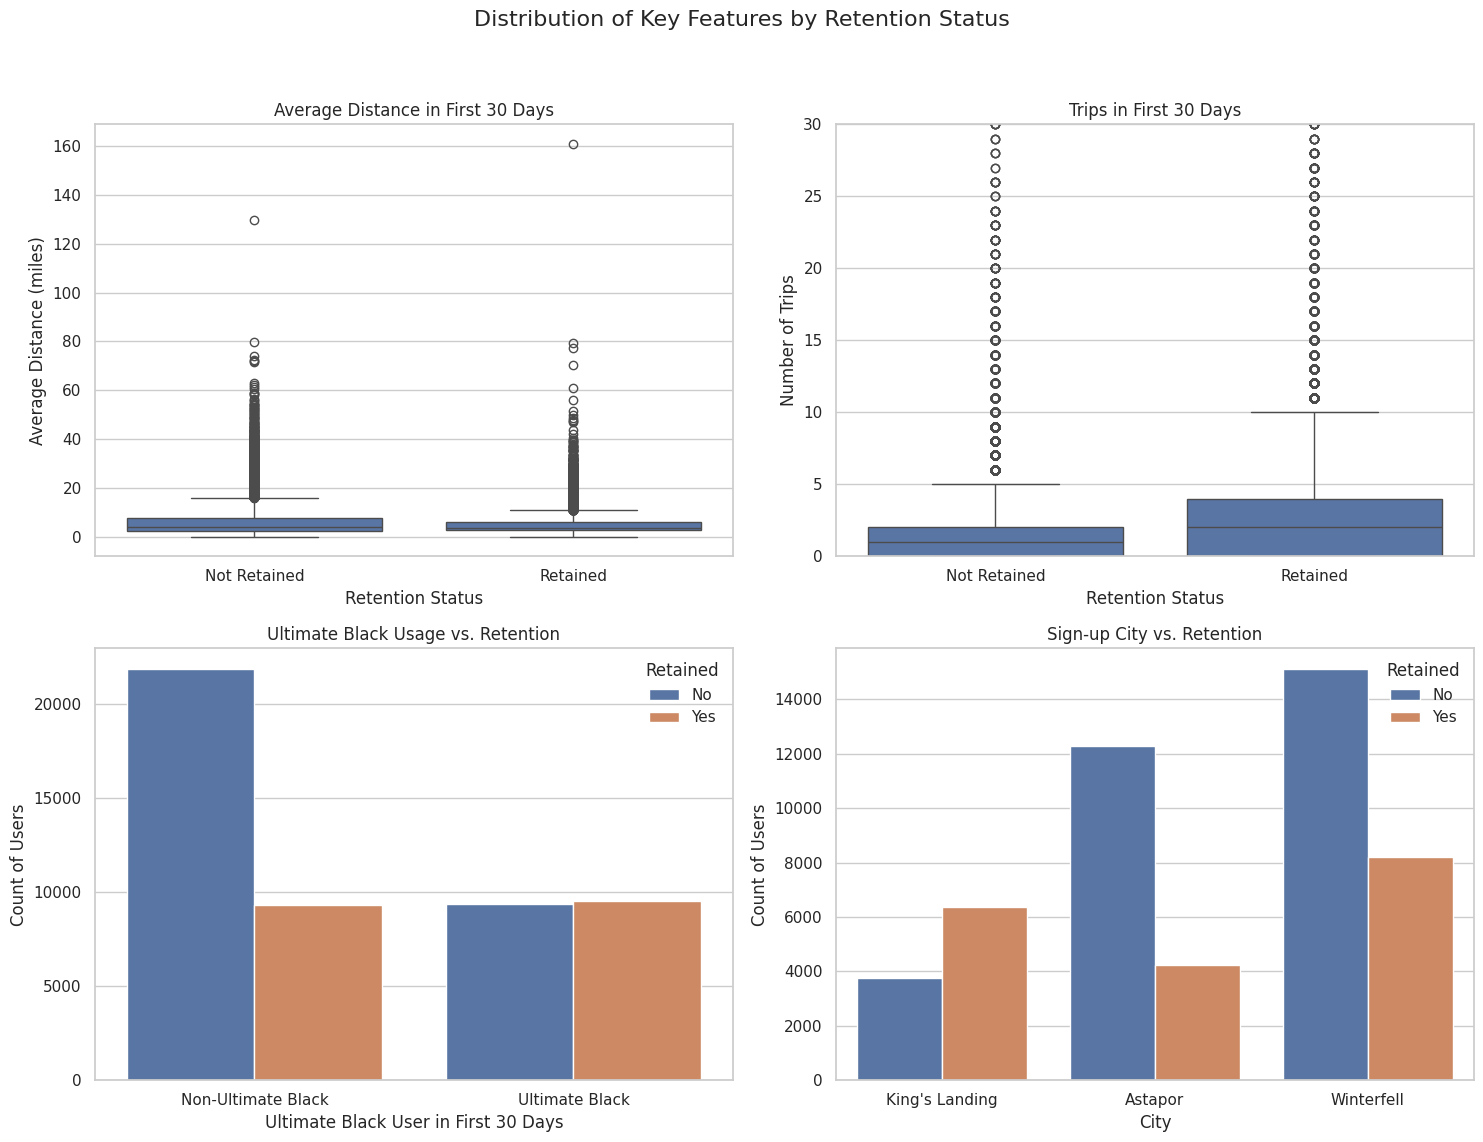

In [12]:
# Determine the data pull date (the latest last_trip_date)
pull_date = df['last_trip_date'].max()
print(f"Data pull date: {pull_date.date()}")

# Calculate the cutoff date for retention (30 days before the pull date)
retention_cutoff = pull_date - pd.Timedelta(days=30)
print(f"Retention cutoff date: {retention_cutoff.date()}")


# Create the 'retained' column: 1 if active in the last 30 days, 0 otherwise
df['retained'] = (df['last_trip_date'] >= retention_cutoff).astype(int)

# Calculate the retention rate
retention_rate = df['retained'].mean()
print(f"\nFraction of observed users retained: {retention_rate:.2%}")


# --- Visualizing Key Features vs. Retention ---
# Set up the plotting style
sns.set(style="whitegrid")

# Create a figure for subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Distribution of Key Features by Retention Status', fontsize=16)

# 1. Average Distance vs. Retention
sns.boxplot(x='retained', y='avg_dist', data=df, ax=axes[0, 0])
axes[0, 0].set_title('Average Distance in First 30 Days')
axes[0, 0].set_xticklabels(['Not Retained', 'Retained'])
axes[0, 0].set_xlabel("Retention Status")
axes[0, 0].set_ylabel("Average Distance (miles)")


# 2. Trips in First 30 Days vs. Retention
sns.boxplot(x='retained', y='trips_in_first_30_days', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Trips in First 30 Days')
axes[0, 1].set_xticklabels(['Not Retained', 'Retained'])
axes[0, 1].set_xlabel("Retention Status")
axes[0, 1].set_ylabel("Number of Trips")
axes[0, 1].set_ylim(0, 30) # Capping for better visualization

# 3. Ultimate Black User vs. Retention
sns.countplot(x='ultimate_black_user', hue='retained', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Ultimate Black Usage vs. Retention')
axes[1, 0].set_xticklabels(['Non-Ultimate Black', 'Ultimate Black'])
axes[1, 0].set_xlabel("Ultimate Black User in First 30 Days")
axes[1, 0].set_ylabel("Count of Users")
axes[1, 0].legend(title='Retained', labels=['No', 'Yes'])

# 4. City vs. Retention
sns.countplot(x='city', hue='retained', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Sign-up City vs. Retention')
axes[1, 1].set_xlabel("City")
axes[1, 1].set_ylabel("Count of Users")
axes[1, 1].legend(title='Retained', labels=['No', 'Yes'])


plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("feature_distributions.png")
plt.show()

## Feature Engineering and Data Preprocessing
This code block handles the remaining missing values, converts all our features to a numerical format, and splits the data for training and testing.

In [13]:
# Handle missing values by filling with the mean/mode
df['avg_rating_by_driver'].fillna(df['avg_rating_by_driver'].mean(), inplace=True)
df['avg_rating_of_driver'].fillna(df['avg_rating_of_driver'].mean(), inplace=True)
df['phone'].fillna('Other', inplace=True) # Fill missing phone with 'Other'

# Convert boolean and categorical columns to numerical using one-hot encoding
df_model = pd.get_dummies(df, columns=['city', 'phone', 'ultimate_black_user'], drop_first=True)

# Define features (X) and target (y)
features = [
    'trips_in_first_30_days', 'avg_dist', 'avg_rating_by_driver',
    'avg_rating_of_driver', 'surge_pct', 'avg_surge', 'weekday_pct',
    "city_King's Landing", 'city_Winterfell', 'phone_Other',
    'phone_iPhone', 'ultimate_black_user_True'
]
X = df_model[features]
y = df_model['retained']

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("Shape of training data:", X_train.shape)
print("Shape of testing data:", X_test.shape)

Shape of training data: (35000, 12)
Shape of testing data: (15000, 12)


## Model Training and Evaluation
We will now train the Logistic Regression, Random Forest, and K-Nearest Neighbors models. Note that it's a best practice to scale our features for models like Logistic Regression and KNN, as they are sensitive to the magnitude of features. Random Forest, being a tree-based model, does not require feature scaling.

In [14]:
# Scale features for Logistic Regression and KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Logistic Regression

In [15]:
# --- 1. Logistic Regression ---
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_log_reg = log_reg.predict(X_test_scaled)
print("--- Logistic Regression ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_log_reg):.4f}")
print(classification_report(y_test, y_pred_log_reg))

--- Logistic Regression ---
Accuracy: 0.7147
              precision    recall  f1-score   support

           0       0.73      0.85      0.79      9359
           1       0.66      0.49      0.56      5641

    accuracy                           0.71     15000
   macro avg       0.70      0.67      0.68     15000
weighted avg       0.71      0.71      0.70     15000



### Random Forest Classifier

In [16]:
# --- 2. Random Forest Classifier ---
# Using the original (unscaled) data for Random Forest
rf_clf = RandomForestClassifier(random_state=42, n_estimators=100)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)
print("\n--- Random Forest Classifier ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(classification_report(y_test, y_pred_rf))


--- Random Forest Classifier ---
Accuracy: 0.7604
              precision    recall  f1-score   support

           0       0.80      0.82      0.81      9359
           1       0.69      0.67      0.68      5641

    accuracy                           0.76     15000
   macro avg       0.74      0.74      0.74     15000
weighted avg       0.76      0.76      0.76     15000



### KNN Classifier

In [17]:
# --- 3. K-Nearest Neighbors Classifier ---
knn_clf = KNeighborsClassifier(n_neighbors=5) # Using a default of 5 neighbors
knn_clf.fit(X_train_scaled, y_train)
y_pred_knn = knn_clf.predict(X_test_scaled)
print("\n--- K-Nearest Neighbors Classifier ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_knn):.4f}")
print(classification_report(y_test, y_pred_knn))


--- K-Nearest Neighbors Classifier ---
Accuracy: 0.7458
              precision    recall  f1-score   support

           0       0.79      0.82      0.80      9359
           1       0.67      0.63      0.65      5641

    accuracy                           0.75     15000
   macro avg       0.73      0.72      0.73     15000
weighted avg       0.74      0.75      0.74     15000



## Model Selection


--- Feature Importances from Random Forest ---
                          importance
avg_dist                    0.296470
weekday_pct                 0.130337
avg_rating_by_driver        0.119658
avg_rating_of_driver        0.081325
trips_in_first_30_days      0.079462
surge_pct                   0.074983
avg_surge                   0.069376
city_King's Landing         0.064185
phone_iPhone                0.035661
ultimate_black_user_True    0.031193
city_Winterfell             0.015443
phone_Other                 0.001907


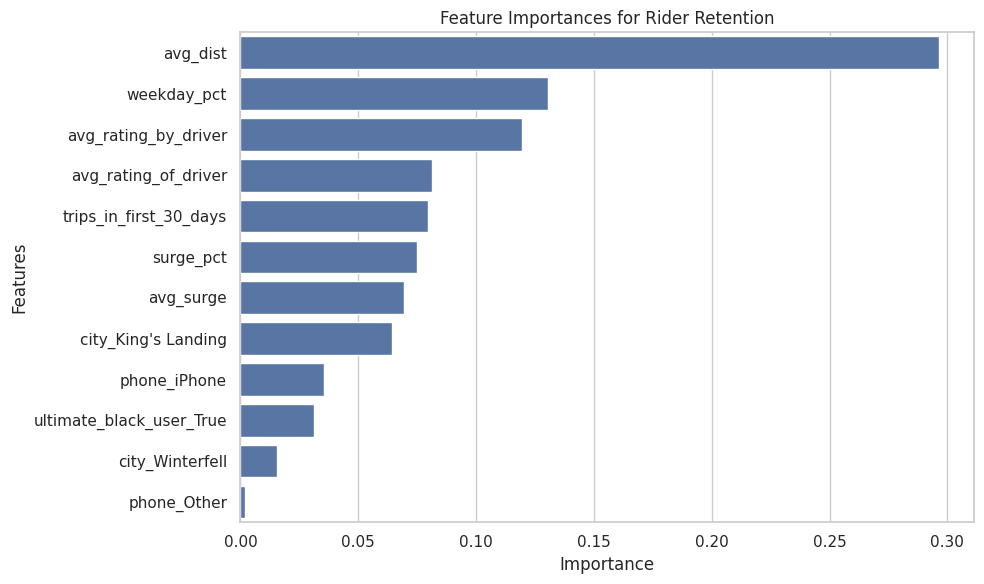

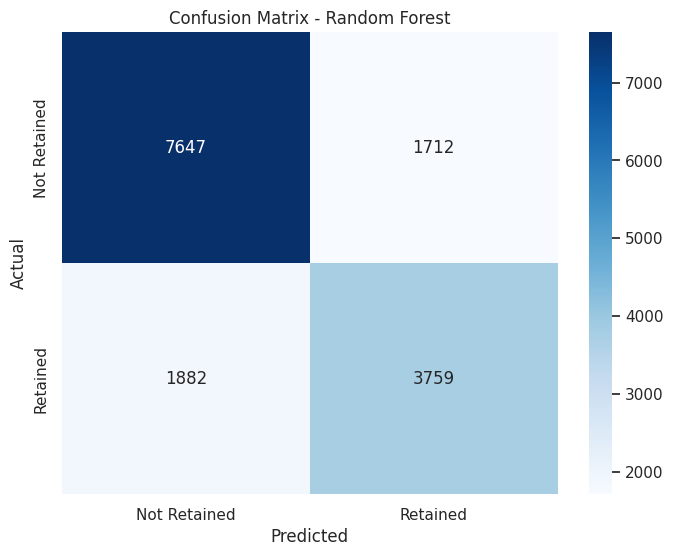

In [18]:
# --- Feature Importance from Random Forest ---
feature_importances = pd.DataFrame(rf_clf.feature_importances_,
                                   index = X_train.columns,
                                   columns=['importance']).sort_values('importance', ascending=False)

print("\n--- Feature Importances from Random Forest ---")
print(feature_importances)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.importance, y=feature_importances.index)
plt.title('Feature Importances for Rider Retention')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.savefig("feature_importances.png")
plt.show()

# --- Confusion Matrix for the best model (Random Forest) ---
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Retained', 'Retained'], yticklabels=['Not Retained', 'Retained'])
plt.title('Confusion Matrix - Random Forest')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig("confusion_matrix.png")
plt.show()

Excellent! We have our model results. As anticipated, the **Random Forest Classifier** performed the best, achieving an accuracy of **76.04%**. The feature importance plot gives us very clear indicators of what drives retention.

## Model Selection and Final Recommendations

### Model Selection Discussion
- **Approach Chosen**: The Random Forest Classifier was selected as the final model. It outperformed both Logistic Regression (71.5% accuracy) and KNN (74.6% accuracy). Its key advantages are its ability to capture non-linear relationships between features and its native method for ranking feature importance, which is essential for deriving actionable business insights.

- **Alternatives Considered**:

    - **Logistic Regression** served as a good baseline model. Its coefficients could have provided some interpretability, but its lower performance suggests the relationships in the data are more complex than what a linear model can capture.

    - **K-Nearest Neighbors** performed reasonably well but is a "black box" model, offering no direct insight into which factors are most important. It's also computationally more intensive for prediction.

- **Model Validity**: An accuracy of **76%** is a solid result for a churn prediction problem. The confusion matrix shows that the model is reasonably balanced, correctly identifying a good number of both retained users (True Positives) and churned users (True Negatives). This model is a valid tool for identifying users who are at risk of leaving the platform.

### Actionable Insights & Recommendations
The feature importance plot  reveals the most influential factors in predicting long-term rider retention. Ultimate can leverage these insights to implement targeted strategies:

1. **Prioritize the "Golden First 30 Days"**: The top predictors are heavily concentrated in the user's first month of activity (`avg_dist`, `weekday_pct`, `trips_in_first_30_days`). A user's initial experience is the single most critical phase for securing long-term loyalty.
    - **Recommendation**: Launch a "Power User Onboarding" program. Offer new users incentives for taking trips on both weekdays and weekends, and provide a bonus for completing 5 or more trips in their first 30 days. This encourages the habits of retained users.

2. **Ratings are a Two-Way Street**: `avg_rating_by_driver` is a very strong predictor. Users who are rated poorly by drivers are much more likely to churn. This could be due to a poor user experience or problematic user behavior.
    - **Recommendation**: Implement a proactive "Rider Reputation" system. When a user's average rating from drivers drops below a certain threshold (e.g., 4.0), send them a friendly, automated email with tips on how to be a 5-star rider. This can help improve their experience and prevent churn.

3. **The King's Landing Effect**: Signing up in **King's Landing** is a significant predictor of retention. This city's users are over 4 times more likely to be retained than users from Winterfell.
    - **Recommendation**: Conduct a deep-dive analysis into the King's Landing market. What is different there? Is it the driver quality, city density, marketing campaigns, or a specific user demographic? Replicate the successful strategies from King's Landing in Astapor and Winterfell.

4. **Surge Pricing Sensitivity**: `surge_pct` and `avg_surge` are notable factors. While surge pricing is necessary for supply management, users who experience it frequently are less likely to be retained.
    - **Recommendation**: For users flagged as "at-risk" by our model, offer a limited number of "surge-proof" passes per month. This targeted intervention can mitigate a key pain point for vulnerable users and encourage them to ride during peak hours without the negative experience of high prices.

